# Fig. 4b — DBO sea-ice phenology on ice-years (Bootstrap) with the NSIDC-0747 retreat check

Standalone, top-to-bottom notebook. It **does not stream** anything: it reuses the daily box-mean
sea-ice concentration already built by `07_sea-ice-ssmi-and-nsidc0747.ipynb` (products pickle or streaming checkpoint
in your home directory) and, optionally, the NSIDC-0747 products pickle built by
`07_sea-ice-ssmi-and-nsidc0747.ipynb` section 4.

**What it computes.** Per DBO box and ice-year (1 Mar → end Feb, the NSIDC-0747 convention):
day of retreat (last ≥15% → <15% crossing before the May–Nov minimum), day of advance (first
<15% → ≥15% crossing after it) and open-water duration, from NSIDC-0079 Bootstrap v4 box-mean
daily SIC after a 15-day rolling mean, ≥100 valid days per season, 7-day gap interpolation for the
SMMR every-other-day era. This fixes the calendar-year truncation of the old phenology cell, which
dropped January/February freeze-ups.

**Outputs** (in `paper_figures/` next to this notebook): **Figure 4.2** `fig4_2_day_of_retreat_bootstrap_vs_nsidc0747.png/.pdf`,
the supplementary three-indicator figure `figS_phenology_iceyear_bootstrap_vs_nsidc0747.png/.pdf`, CSVs, and
ready-to-paste rows for the Fig. 8 scorecard (assembled outside this repository).

**Inputs expected in `~`:** `ssmi_seaice_products.pkl` *or* `ssmi_seaice_ckpt.pkl` (required);
`nsidc0747_retreat_products.pkl` (optional overlay).


## 1. Imports

In [14]:
import pickle, warnings
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
from pyresample import AreaDefinition
from matplotlib.path import Path as MplPath
import matplotlib.pyplot as plt
from scipy.stats import theilslopes, kendalltau, norm
warnings.filterwarnings("ignore")
print("imports OK")

imports OK


## 2. Grid, DBO boxes, cache paths (identical to `07_sea-ice-ssmi-and-nsidc0747.ipynb` section 2)

In [15]:
# EASE-Grid 2.0 North subset, 4 km — must match the grid the pickles were built on
dbo_area = AreaDefinition(
    area_id="ease2_north_dbo_4km",
    description="EASE-Grid 2.0 North subset: Aleutians -> Beaufort (DBO1-8), 4 km",
    proj_id="EPSG:6931",
    projection={"proj":"laea","lat_0":90,"lon_0":0,"x_0":0,"y_0":0,"datum":"WGS84","units":"m"},
    width=906, height=845, area_extent=(-3_624_000, 992_000, 0, 4_372_000))

CKPT_PATH  = Path.home() / "ssmi_seaice_ckpt.pkl"        # streaming checkpoint (box_rows etc.)  # add your path
CACHE_PATH = Path.home() / "ssmi_seaice_products.pkl"    # finished products, if ever saved  # add your path

DBO_BOXES = {
    "DBO1": [(63.769462,-172.312422),(61.945988,-172.186927),(61.846516,-175.790978),(63.662718,-176.147111)],
    "DBO2": [(65.107747,-170.865176),(65.097001,-167.859549),(64.481828,-167.907758),(64.493658,-170.840669)],
    "DBO3": [(66.785880,-171.330008),(68.608869,-171.419334),(68.572412,-166.481029),(66.752281,-166.755808)],
    "DBO4": [(71.994000,-164.226000),(71.801000,-159.729000),(70.641000,-160.305000),(70.821000,-164.556000)],
    "DBO5": [(71.807730,-158.537691),(71.635583,-155.931220),(71.110941,-156.307277),(71.278277,-158.847920)],
    "DBO6": [(71.850000,-150.108000),(70.890000,-150.976000),(71.159000,-153.865000),(72.119000,-152.980000)],
    "DBO7": [(70.868000,-141.528000),(69.946000,-142.679000),(70.333000,-145.439000),(71.253000,-144.256000)],
    "DBO8": [(70.834000,-125.155000),(70.049000,-126.997000),(70.664000,-129.354000),(71.442000,-127.431000)],
}

print(f"grid {dbo_area.shape} | checkpoint exists: {CKPT_PATH.exists()} | products exist: {CACHE_PATH.exists()}")

grid (845, 906) | checkpoint exists: True | products exist: False


## 3. DBO box masks on the EASE-2 grid (identical to section 5)

In [16]:
lons2d, lats2d = dbo_area.get_lonlats()
grid_pts = np.column_stack([lons2d.ravel(), lats2d.ravel()])
box_masks = {name: MplPath([(lo,la) for la,lo in corners] + [(corners[0][1], corners[0][0])])
                       .contains_points(grid_pts).reshape(lons2d.shape)
             for name, corners in DBO_BOXES.items()}
for name, m in box_masks.items():
    print(f"  {name}: {int(m.sum()):>6,} grid cells")

  DBO1:  2,412 grid cells
  DBO2:    605 grid cells
  DBO3:  2,561 grid cells
  DBO4:  1,293 grid cells
  DBO5:    351 grid cells
  DBO6:    739 grid cells
  DBO7:    773 grid cells
  DBO8:    760 grid cells


## 4. Trend helpers — Theil–Sen slope, AR(1)-adjusted Mann–Kendall p (identical to section 9)

In [17]:
def _lag1(x):
    x = np.asarray(x, float); a, b = x[1:], x[:-1]; v = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[v], b[v])[0, 1]) if v.sum() >= 5 else 0.0
def mk(x, y, minn=20):
    v = np.isfinite(x) & np.isfinite(y); x, y = x[v], y[v]; n = len(x)
    if n < minn: return dict(slope=np.nan, intercept=np.nan, p=np.nan, p_naive=np.nan, n=n)
    slope, intercept, _, _ = theilslopes(y, x)
    tau, p_naive = kendalltau(x, y)
    sl, ic = np.polyfit(x, y, 1); phi = _lag1(y - (sl*x + ic))
    ne = n*(1-phi)/(1+phi) if (abs(phi) < 1 and phi != 0) else n
    p = 2*(1 - norm.cdf(abs(tau/np.sqrt(2*(2*ne+5)/(9*ne*(ne-1)))))) if ne > 4 else np.nan
    return dict(slope=slope, intercept=intercept, p=p, p_naive=p_naive, n=n)
def _stars(p):
    return ("***" if p<0.001 else "**" if p<0.01 else "*" if p<0.05 else "ns") if np.isfinite(p) else "n/a"
print("helpers ready")

helpers ready


## 5. Load the daily box-mean SIC (no streaming; identical to the section-14 loader)

In [18]:
ny, nx = dbo_area.shape
if CACHE_PATH.exists():
    _d = pickle.load(open(CACHE_PATH, "rb"))
    box_ts = _d["box_ts"]
    print(f"loaded finished products from {CACHE_PATH.name}")
elif CKPT_PATH.exists():
    _ck = pickle.load(open(CKPT_PATH, "rb"))
    box_rows = _ck["box_rows"]
    dates = sorted(box_rows); tcoord = np.array([np.datetime64(d.isoformat()) for d in dates])
    box_ts = {n: xr.DataArray(np.array([box_rows[d][n] for d in dates]), dims="time", coords={"time": tcoord})
              for n in DBO_BOXES}
    print(f"rebuilt box_ts from checkpoint {CKPT_PATH.name}: {len(box_rows)} days ({dates[0]} -> {dates[-1]})")
else:
    raise FileNotFoundError("Neither ~/ssmi_seaice_products.pkl nor ~/ssmi_seaice_ckpt.pkl found — "
                            "run 07_sea-ice-ssmi-and-nsidc0747.ipynb section 6 once on this machine to stream the record.")
print("boxes with data:", [n for n in box_ts if int(np.isfinite(np.asarray(box_ts[n])).sum()) > 0])
_probe = np.nanmax(np.asarray(box_ts[list(box_ts)[0]], float))
if _probe < 20: print("!! WARNING: values max out below 20 — this does not look like sea-ice concentration in %")

rebuilt box_ts from checkpoint ssmi_seaice_ckpt.pkl: 16802 days (1980-01-01 -> 2025-12-31)
boxes with data: ['DBO1', 'DBO2', 'DBO3', 'DBO4', 'DBO5', 'DBO6', 'DBO7', 'DBO8']


## 6. Phenology computation + supplementary figure (retreat, advance, open water) + scorecard rows

Computes `PH` (ice-year phenology per box), loads the NSIDC-0747 overlay, writes the **supplementary**
three-indicator figure `paper_figures/figS_phenology_iceyear_bootstrap_vs_nsidc0747.png/.pdf`, the CSVs, and prints
the ice-year trends, calendar-vs-ice-year comparison, Bootstrap-vs-0747 agreement, and the scorecard rows.
Figure 4.2 itself is made in the next cell from the same `PH`.


In [19]:
# === Supplement — full sea-ice phenology (retreat, advance, open water) on ICE-YEARS (1 Mar -> end Feb) + NSIDC-0747 overlay ==========
# Why this cell exists: the section-13 phenology works on calendar years, so the advance search
# stops on 31 Dec. Seasons that freeze in Jan/Feb (DBO1-2, increasingly in recent years) were
# therefore dropped from advance and open-water duration - exactly the extreme seasons the trend
# is about. Here every season runs 1 Mar Y -> last day of Feb Y+1 (the NSIDC-0747 convention).
#   retreat  = last  >=15% -> <15% crossing before the May-Nov minimum
#   advance  = first <15% -> >=15% crossing after it (may fall in Jan/Feb of Y+1)
#   open     = advance - retreat
# Day axis = days since 1 Jan Y, so Jan/Feb of Y+1 plot as 366+. 15-day centred rolling mean and
# the 7-day SMMR gap interpolation are unchanged. Seasons whose window is not fully observed yet
# are skipped (no partial current season).
# The NSIDC-0747 box-mean day of retreat (CDR-based, per 25 km pixel, then box-averaged) is
# overlaid as the independent check. Needs: box_ts, box_masks, DBO_BOXES, mk, _stars
# (sections 2, 5, 9 and 14/load). Writes paper_figures/figS_* + fig4b_*.csv and prints scorecard-ready rows.
import pickle
from pathlib import Path
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

THRESH, SMOOTH, MINOBS = 15.0, 15, 100
MIN_SEARCH = (120, 330)                     # DOY window in which the summer minimum is sought
ICEYEAR_START = (3, 1)                      # 1 March, as in NSIDC-0747
NSIDC0747_PKL = Path.home() / "nsidc0747_retreat_products.pkl"   # from 1_pull_data/07_sea-ice-ssmi-and-nsidc0747.ipynb  # add your path
OUTDIR = Path("paper_figures"); OUTDIR.mkdir(exist_ok=True)
SCORECARD_BOXES = ["DBO1", "DBO2", "DBO3", "DBO4", "DBO5", "DBO6", "DBO7", "DBO8"]   # the Fig. 8 scorecard; first five = the Fig. 8 scorecard

for _need in ("box_ts", "box_masks", "DBO_BOXES", "mk", "_stars"):
    if _need not in globals():
        raise NameError(f"`{_need}` is not defined - run sections 2, 5, 9 and 14 (load) first")

def _da(obj):
    """Coerce a box_ts entry to a DataArray regardless of cache vintage (same as section 15)."""
    if isinstance(obj, xr.DataArray): return obj
    if isinstance(obj, xr.Dataset):  return obj[list(obj.data_vars)[0]]
    if isinstance(obj, dict):
        for k in ("daily_mean", "mean", "value"):
            if k in obj: return _da(obj[k])
        return _da(next(iter(obj.values())))
    raise TypeError(f"cannot coerce {type(obj).__name__}")

def _season_phenology(a, day):
    """a: smoothed SIC (%); day: days since 1 Jan of the season's start year (Jan/Feb of Y+1 -> 366+)."""
    fin = np.isfinite(a)
    mid = (day >= MIN_SEARCH[0]) & (day <= MIN_SEARCH[1]) & fin
    if fin.sum() < MINOBS or not mid.any(): return np.nan, np.nan
    imin = np.where(mid)[0][np.argmin(a[mid])]
    if a[imin] >= THRESH: return np.nan, np.nan          # never opens -> no retreat / advance
    retreat = advance = np.nan
    for k in range(imin, 0, -1):                          # last spring crossing  >=T -> <T
        if np.isfinite(a[k-1]) and np.isfinite(a[k]) and a[k-1] >= THRESH > a[k]:
            retreat = day[k]; break
    for k in range(imin, len(a) - 1):                     # first fall/winter crossing <T -> >=T
        if np.isfinite(a[k]) and np.isfinite(a[k+1]) and a[k] < THRESH <= a[k+1]:
            advance = day[k+1]; break
    return retreat, advance

def phenology_iceyear(s):
    ser = _da(s).to_series(); ser.index = pd.to_datetime(ser.index); ser = ser.sort_index()
    last_obs = ser.dropna().index.max(); out = {}
    for Y in range(int(ser.index.year.min()), int(ser.index.year.max()) + 1):
        t0 = pd.Timestamp(Y, *ICEYEAR_START)
        t1 = pd.Timestamp(Y + 1, *ICEYEAR_START) - pd.Timedelta(days=1)
        if t1 > last_obs: continue                        # season not fully observed yet -> skip
        full = pd.date_range(t0, t1, freq="D")
        v  = ser.reindex(full).interpolate(limit=7, limit_area="inside")   # bridge SMMR every-other-day gaps
        sm = v.rolling(SMOOTH, center=True, min_periods=SMOOTH // 2).mean().values
        day = ((full - pd.Timestamp(Y, 1, 1)).days + 1).values.astype(float)
        r, a = _season_phenology(sm, day)
        out[Y] = (r, a, a - r if np.isfinite(r) and np.isfinite(a) else np.nan)
    return pd.DataFrame(out, index=["retreat", "advance", "open"]).T

def phenology_calyear(s):
    """Section-13 behaviour (calendar year), kept only for the before/after comparison."""
    ser = _da(s).to_series(); ser.index = pd.to_datetime(ser.index); out = {}
    for yr, g in ser.groupby(ser.index.year):
        full = pd.date_range(f"{int(yr)}-01-01", f"{int(yr)}-12-31", freq="D")
        v  = g.reindex(full).interpolate(limit=7, limit_area="inside")
        sm = v.rolling(SMOOTH, center=True, min_periods=SMOOTH // 2).mean().values
        r, a = _season_phenology(sm, full.dayofyear.values.astype(float))
        out[int(yr)] = (r, a, a - r if np.isfinite(r) and np.isfinite(a) else np.nan)
    return pd.DataFrame(out, index=["retreat", "advance", "open"]).T

PH  = {n: phenology_iceyear(box_ts[n]) for n in DBO_BOXES if n in box_ts and _da(box_ts[n]).size > 0}
PHc = {n: phenology_calyear(box_ts[n]) for n in PH}

# --- NSIDC-0747 box-mean day of retreat, same EASE-2 grid and box masks (optional overlay) ---
steele = None
if NSIDC0747_PKL.exists():
    _d7 = pickle.load(open(NSIDC0747_PKL, "rb"))
    A7 = np.asarray(_d7["prod"]["DOR"].values, float); yrs7 = np.asarray(_d7["years"], int)
    steele = pd.DataFrame({n: [np.nanmean(A7[k][box_masks[n]]) if np.isfinite(A7[k][box_masks[n]]).any() else np.nan
                               for k in range(A7.shape[0])] for n in PH}, index=yrs7)
    print(f"NSIDC-0747 overlay loaded: ice-years {yrs7.min()}-{yrs7.max()}")
else:
    print(f"NSIDC-0747 pickle not found at {NSIDC0747_PKL}; panels show Bootstrap only. "
          "Run 1_pull_data/07_sea-ice-ssmi-and-nsidc0747.ipynb section 4 once to create it.")

# ------------------------------------------------------------------ figure ---------------------
OI = {"blue": "#0072B2", "green": "#009E73", "orange": "#D55E00", "ink": "#222222"}
FS_TITLE, FS_STAT, FS_LAB, FS_TICK, FS_LEG = 20, 13, 17, 14, 14
MONTH_TICKS = [(60, "Mar"), (121, "May"), (182, "Jul"), (244, "Sep"), (305, "Nov"), (366, "Jan"), (397, "Feb")]

fig, axes = plt.subplots(2, 4, figsize=(26, 11.5), sharex=True, sharey=True); axes = axes.ravel()
rows, cmp_rows = [], []
for ax, name in zip(axes, PH):
    ph = PH[name]; x = ph.index.values.astype(float)
    ok = np.isfinite(ph["retreat"].values) & np.isfinite(ph["advance"].values)
    ax.fill_between(x, ph["retreat"].values, ph["advance"].values, where=ok, color="0.92", lw=0, zorder=0)
    stats_txt = []
    for col, color, lab in [("retreat", OI["green"], "retreat"), ("advance", OI["orange"], "advance")]:
        y = ph[col].values; m = np.isfinite(y)
        ax.plot(x[m], y[m], "o-", color=color, mec="white", mew=0.5, ms=5.5, lw=1.2, zorder=3)
        r = mk(x[m], y[m])
        if np.isfinite(r["slope"]):
            sig = np.isfinite(r["p"]) and r["p"] < 0.05
            ax.plot(x[m], r["intercept"] + r["slope"] * x[m], "-" if sig else "--", color=color, lw=2.8, zorder=4)
            stats_txt.append(f"{lab} {r['slope']*10:+.1f} d dec$^{{-1}}$ {_stars(r['p'])}")
        rows.append((name, col, r["slope"] * 10, r["p"], _stars(r["p"]), r["n"]))
    yo = ph["open"].values; mo = np.isfinite(yo); ro = mk(x[mo], yo[mo])
    rows.append((name, "open_water", ro["slope"] * 10, ro["p"], _stars(ro["p"]), ro["n"]))
    if np.isfinite(ro["slope"]): stats_txt.append(f"open water {ro['slope']*10:+.1f} d dec$^{{-1}}$ {_stars(ro['p'])}")
    if steele is not None:
        s7 = steele[name]; x7 = s7.index.values.astype(float); m7 = np.isfinite(s7.values)
        ax.plot(x7[m7], s7.values[m7], "s", color=OI["blue"], mfc="none", mew=1.4, ms=6, zorder=2)
        r7 = mk(x7[m7], s7.values[m7])
        if np.isfinite(r7["slope"]):
            ax.plot(x7[m7], r7["intercept"] + r7["slope"] * x7[m7], ":", color=OI["blue"], lw=2.6, zorder=4)
            stats_txt.append(f"NSIDC-0747 retreat {r7['slope']*10:+.1f} d dec$^{{-1}}$ {_stars(r7['p'])}")
        both = pd.concat([ph["retreat"], s7], axis=1, keys=["boot", "s0747"]).dropna()
        if len(both) >= 5:
            xb = both.index.values.astype(float)
            rb, rc = mk(xb, both["boot"].values), mk(xb, both["s0747"].values)
            cmp_rows.append((name, len(both), int(both.index.min()), int(both.index.max()),
                             float((both["boot"] - both["s0747"]).mean()),
                             float(np.corrcoef(both["boot"], both["s0747"])[0, 1]),
                             rb["slope"] * 10, rb["p"], rc["slope"] * 10, rc["p"]))
    ax.text(0.03, 0.97, name, transform=ax.transAxes, fontsize=FS_TITLE, fontweight="bold", va="top", ha="left")
    ax.text(0.97, 0.03, "\n".join(stats_txt), transform=ax.transAxes, fontsize=FS_STAT, va="bottom", ha="right",
            color="0.2", path_effects=[pe.withStroke(linewidth=3, foreground="white")])
    ax.tick_params(labelsize=FS_TICK); ax.grid(alpha=0.2)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
axes[0].set_ylim(-25, 425)                     # room below March for the stats block
for ax in axes[::4]:
    ax.set_yticks([d for d, _ in MONTH_TICKS]); ax.set_yticklabels([mth for _, mth in MONTH_TICKS], fontsize=FS_TICK)
    ax.set_ylabel("date within ice-year (1 Mar → end Feb)", fontsize=FS_LAB)
for ax in axes[4:]: ax.set_xlabel("ice-year (year of 1 March)", fontsize=FS_LAB)
handles = [
    Line2D([0], [0], color=OI["green"], marker="o", ms=7, lw=2.4, mec="white", label="retreat, NSIDC-0079 Bootstrap (this study)"),
    Line2D([0], [0], color=OI["orange"], marker="o", ms=7, lw=2.4, mec="white", label="advance, NSIDC-0079 Bootstrap (this study)"),
    Line2D([0], [0], color=OI["blue"], marker="s", mfc="none", mew=1.4, ms=7, lw=0, label="retreat, NSIDC-0747 (Steele et al.), box mean of per-pixel"),
    Line2D([0], [0], color="0.3", lw=2.6, ls="-", label="Theil–Sen trend, p < 0.05"),
    Line2D([0], [0], color="0.3", lw=2.6, ls="--", label="Theil–Sen trend, n.s."),
    Line2D([0], [0], color=OI["blue"], lw=2.6, ls=":", label="NSIDC-0747 trend"),
    Patch(facecolor="0.92", edgecolor="none", label="open-water season (retreat → advance)"),
]
fig.legend(handles=handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.01), fontsize=FS_LEG,
           handlelength=2.2, columnspacing=1.8, frameon=False)
plt.tight_layout(rect=(0, 0.06, 1, 1))
for ext in ("png", "pdf"):
    fig.savefig(OUTDIR / f"figS_phenology_iceyear_bootstrap_vs_nsidc0747.{ext}", dpi=300, bbox_inches="tight")
print(f"saved -> {OUTDIR}/figS_phenology_iceyear_bootstrap_vs_nsidc0747.(png|pdf)")
plt.show()

# ------------------------------------------------------------------ tables ---------------------
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
tbl_ice = pd.DataFrame(rows, columns=["box", "phase", "trend_d_per_decade", "p_AR1", "sig", "n_seasons"]).set_index(["box", "phase"])
print("\n=== ICE-YEAR phenology trends (use these for the scorecard and the text) ===")
print(tbl_ice)

diff_rows = []
for name in PH:
    for col in ("retreat", "advance", "open"):
        yi, yc = PH[name][col], PHc[name][col]
        ri = mk(yi.index.values.astype(float), yi.values); rc = mk(yc.index.values.astype(float), yc.values)
        common = yi.index.intersection(yc.index)
        recovered = int((np.isfinite(yi.reindex(common).values) & ~np.isfinite(yc.reindex(common).values)).sum())
        diff_rows.append((name, col, rc["slope"] * 10, rc["p"], rc["n"], ri["slope"] * 10, ri["p"], ri["n"], recovered))
tbl_diff = pd.DataFrame(diff_rows, columns=["box", "phase", "cal_trend", "cal_p", "cal_n",
                                            "ice_trend", "ice_p", "ice_n", "seasons_recovered"]).set_index(["box", "phase"])
print("\n=== calendar-year (section 13 / old scorecard) vs ice-year: trend d/decade, p, n ===")
print("seasons_recovered = seasons with a value under ice-years that were NaN under calendar years")
print(tbl_diff)

if cmp_rows:
    tbl_cmp = pd.DataFrame(cmp_rows, columns=["box", "n_common", "yr0", "yr1", "mean_diff_boot_minus_0747_days",
                                              "r_interannual", "boot_trend_common", "boot_p", "s0747_trend_common", "s0747_p"]).set_index("box")
    print("\n=== Bootstrap (this study) vs NSIDC-0747 day of retreat on common ice-years ===")
    print("mean_diff > 0 means the Bootstrap box-mean retreats LATER than the box-averaged per-pixel NSIDC-0747 date")
    print(tbl_cmp)
    tbl_cmp.to_csv(OUTDIR / "fig4b_retreat_bootstrap_vs_nsidc0747.csv")
tbl_ice.to_csv(OUTDIR / "fig4b_phenology_iceyear_trends.csv"); tbl_diff.to_csv(OUTDIR / "fig4b_calendar_vs_iceyear.csv")

print("\n=== paste into the Fig. 8 scorecard (replaces the three ICE rows; DBO1-8; drop the last three tuples for the Fig. 8 scorecard) ===")
def _pairs(phase):
    out = []
    for b in SCORECARD_BOXES:
        if (b, phase) in tbl_ice.index:
            t, p = tbl_ice.loc[(b, phase), "trend_d_per_decade"], tbl_ice.loc[(b, phase), "p_AR1"]
            out.append(f"({t:.1f}, {max(p, 0.0005):.4g})" if np.isfinite(t) else "(np.nan, np.nan)")
        else: out.append("(np.nan, np.nan)")
    return "[" + ", ".join(out) + "]"
print('    # --- 2_figures/fig04b_sea-ice-day-of-retreat.ipynb (ICE-YEAR phenology, 1 Mar -> end Feb)')
print(f'    ("ICE", "Open-water duration", "SSM/I · NSIDC-0079 Bootstrap v4", "d/dec", "{{:+.1f}}",\n     {_pairs("open_water")}),')
print(f'    ("ICE", "Day of ice retreat", "SSM/I · NSIDC-0079 Bootstrap v4 · earlier = −", "d/dec", "{{:+.1f}}",\n     {_pairs("retreat")}),')
print(f'    ("ICE", "Day of ice advance", "SSM/I · NSIDC-0079 Bootstrap v4 · later = +", "d/dec", "{{:+.1f}}",\n     {_pairs("advance")}),')

NSIDC-0747 overlay loaded: ice-years 1979-2023
saved -> paper_figures/figS_phenology_iceyear_bootstrap_vs_nsidc0747.(png|pdf)



=== ICE-YEAR phenology trends (use these for the scorecard and the text) ===
                 trend_d_per_decade  p_AR1  sig  n_seasons
box  phase                                                
DBO1 retreat                 -2.810  0.303   ns         45
     advance                  5.683  0.001  ***         45
     open_water               8.730  0.042    *         45
DBO2 retreat                 -3.750  0.048    *         45
     advance                  6.458  0.000  ***         45
     open_water              10.000  0.001   **         45
DBO3 retreat                 -5.455  0.002   **         45
     advance                  6.985  0.000  ***         45
     open_water              12.500  0.000  ***         45
DBO4 retreat                -12.804  0.000  ***         40
     advance                 13.038  0.000  ***         40
     open_water              26.283  0.000  ***         40
DBO5 retreat                -10.312  0.000  ***         39
     advance                 10.000  

## 7. Figure 4.2 — day of retreat per box (existing style), NSIDC-0747 extended with this study

Same layout as the current Figure 4.2 (2×4, panel letters, blue NSIDC-0747 box mean with ±1 SD band, orange
Theil–Sen fit). Adds the Bootstrap ice-year retreat in green through 2025; the fit and the bold stat are on the
Bootstrap series, with the NSIDC-0747 trend in blue text for comparison. Writes `paper_figures/fig4_2_*`.


saved -> paper_figures/fig4_2_day_of_retreat_bootstrap_vs_nsidc0747.(png|pdf)


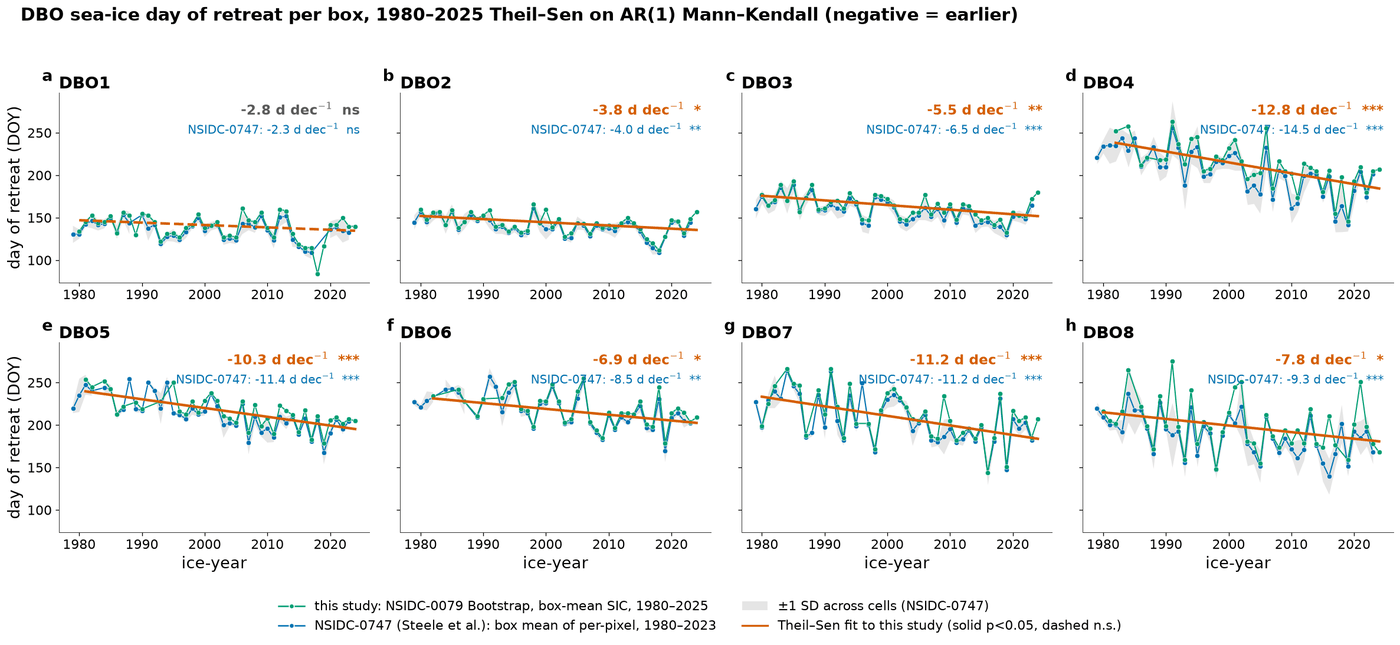


=== Fig. 4.2 numbers: day-of-retreat trends, this study (1980-2025) vs NSIDC-0747 (1980-2023) ===
      boot_trend_d_dec  boot_p boot_sig  boot_n  s0747_trend_d_dec  s0747_p  \
box                                                                           
DBO1            -2.810   0.303       ns      45             -2.261    0.257   
DBO2            -3.750   0.048        *      45             -3.991    0.006   
DBO3            -5.455   0.002       **      45             -6.451    0.000   
DBO4           -12.804   0.000      ***      40            -14.543    0.000   
DBO5           -10.312   0.000      ***      39            -11.362    0.000   
DBO6            -6.854   0.011        *      37             -8.534    0.001   
DBO7           -11.250   0.001      ***      42            -11.189    0.000   
DBO8            -7.778   0.014        *      43             -9.327    0.000   

     s0747_sig  s0747_n  
box                      
DBO1        ns       42  
DBO2        **       44  
DBO3  

In [21]:
# === Fig. 4.2 — day of retreat per box, in the existing Figure 4.2 style ========================
# NSIDC-0747 (Steele et al.): blue box mean of per-pixel day of retreat, grey = ±1 SD across cells,
# ice-years 1980–2023. This study: green = retreat from NSIDC-0079 Bootstrap box-mean SIC on the same
# ice-year definition, 1980–2025 (extends the record two seasons). Orange = Theil–Sen fit to the
# Bootstrap series (solid p<0.05, dashed n.s.), AR(1)-adjusted Mann–Kendall stars; the NSIDC-0747
# trend is given in blue text for comparison. Requires PH, steele, A7, box_masks from the cell above.
import string
import matplotlib as mpl
STYLE = {"figure.dpi": 120, "savefig.dpi": 300, "figure.facecolor": "white", "savefig.bbox": "tight",
         "font.family": "sans-serif", "font.sans-serif": ["Helvetica", "Helvetica Neue", "Arial", "Nimbus Sans", "DejaVu Sans"],
         "font.size": 14, "axes.titlesize": 17, "axes.labelsize": 16, "xtick.labelsize": 13, "ytick.labelsize": 13,
         "legend.fontsize": 13, "axes.linewidth": 0.6, "axes.edgecolor": "0.2", "axes.titlelocation": "left",
         "axes.titleweight": "bold", "axes.titlepad": 4, "axes.spines.top": False, "axes.spines.right": False,
         "xtick.direction": "out", "ytick.direction": "out", "legend.frameon": False, "axes.grid": False,
         "lines.linewidth": 1.4, "lines.markersize": 5}
OI = {"blue": "#0072B2", "green": "#009E73", "orange": "#D55E00"}
if steele is None:
    print("note: NSIDC-0747 pickle not found - Fig. 4.2 will show the Bootstrap series only")

rows42 = []
with mpl.rc_context(STYLE):
    fig, axes = plt.subplots(2, 4, figsize=(20, 9), sharex=True, sharey=True); axes = axes.ravel()
    for k, (ax, name) in enumerate(zip(axes, PH)):
        ph = PH[name]; xb = ph.index.values.astype(float); yb = ph["retreat"].values; mb = np.isfinite(yb)
        r7 = dict(slope=np.nan, p=np.nan, n=0)
        if steele is not None:
            s7 = steele[name]; x7 = s7.index.values.astype(float); y7 = s7.values; m7 = np.isfinite(y7)
            msk = box_masks[name]
            sd7 = np.array([np.nanstd(A7[j][msk]) if np.isfinite(A7[j][msk]).any() else np.nan for j in range(A7.shape[0])])
            ax.fill_between(x7, y7 - sd7, y7 + sd7, color="0.6", alpha=0.25, lw=0, zorder=0)
            ax.plot(x7[m7], y7[m7], "o-", color=OI["blue"], mec="white", mew=0.4, ms=5, lw=1.2, zorder=2)
            r7 = mk(x7[m7], y7[m7])
        ax.plot(xb[mb], yb[mb], "o-", color=OI["green"], mec="white", mew=0.4, ms=5, lw=1.2, zorder=3)
        rb = mk(xb[mb], yb[mb]); sig = np.isfinite(rb["p"]) and rb["p"] < 0.05
        if np.isfinite(rb["slope"]):
            ax.plot(xb[mb], rb["intercept"] + rb["slope"] * xb[mb], "-" if sig else "--", color=OI["orange"], lw=2.6, zorder=4)
            ax.text(0.97, 0.95, f"{rb['slope']*10:+.1f} d dec$^{{-1}}$  {_stars(rb['p'])}", transform=ax.transAxes,
                    ha="right", va="top", fontsize=14, fontweight="bold", color=OI["orange"] if sig else "0.35")
        if np.isfinite(r7["slope"]):
            ax.text(0.97, 0.84, f"NSIDC-0747: {r7['slope']*10:+.1f} d dec$^{{-1}}$  {_stars(r7['p'])}", transform=ax.transAxes,
                    ha="right", va="top", fontsize=12, color=OI["blue"])
        ax.set_title(name, loc="left")
        ax.text(-0.02, 1.04, string.ascii_lowercase[k], transform=ax.transAxes, fontsize=16, fontweight="bold", va="bottom", ha="right")
        ax.tick_params(labelbottom=True)
        rows42.append((name, rb["slope"] * 10, rb["p"], _stars(rb["p"]), rb["n"], r7["slope"] * 10, r7["p"], _stars(r7["p"]), r7["n"]))
    for ax in axes[::4]: ax.set_ylabel("day of retreat (DOY)")
    for ax in axes[4:]: ax.set_xlabel("ice-year")
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    handles = [Line2D([0], [0], color=OI["green"], marker="o", ms=5, lw=1.5, mec="white", label="this study: NSIDC-0079 Bootstrap, box-mean SIC, 1980–2025"),
               Line2D([0], [0], color=OI["blue"], marker="o", ms=5, lw=1.5, mec="white", label="NSIDC-0747 (Steele et al.): box mean of per-pixel, 1980–2023"),
               Patch(facecolor="0.6", alpha=0.25, edgecolor="none", label="±1 SD across cells (NSIDC-0747)"),
               Line2D([0], [0], color=OI["orange"], lw=2.0, label="Theil–Sen fit to this study (solid p<0.05, dashed n.s.)")]
    fig.legend(handles=handles, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.02), fontsize=13, handlelength=2.0, columnspacing=2.0)
    fig.suptitle("DBO sea-ice day of retreat per box, 1980–2025 Theil–Sen on AR(1) Mann–Kendall (negative = earlier)",
                 fontsize=18, x=0.02, ha="left", fontweight="bold")
    plt.tight_layout(rect=(0, 0.07, 1, 0.96))
    for ext in ("png", "pdf"):
        fig.savefig(OUTDIR / f"fig4_2_day_of_retreat_bootstrap_vs_nsidc0747.{ext}", dpi=300, bbox_inches="tight")
    print(f"saved -> {OUTDIR}/fig4_2_day_of_retreat_bootstrap_vs_nsidc0747.(png|pdf)")
    plt.show()

tbl42 = pd.DataFrame(rows42, columns=["box", "boot_trend_d_dec", "boot_p", "boot_sig", "boot_n",
                                      "s0747_trend_d_dec", "s0747_p", "s0747_sig", "s0747_n"]).set_index("box")
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
print("\n=== Fig. 4.2 numbers: day-of-retreat trends, this study (1980-2025) vs NSIDC-0747 (1980-2023) ===")
print(tbl42)
tbl42.to_csv(OUTDIR / "fig4_2_day_of_retreat_trends.csv")